# Walmart Sales Prediction
## CS1783 Artificial Intelligence Programming
### Jacob Shultz, Aidan Gross

### Assignment:

"Develop and train a Long Short-Term Memory (LSTM) neural network using PyTorch to predict future Walmart sales based on historical sales data.

[Walmart M5 Forecasting Dataset](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data)

The model must predict 28 days of future sales rather than simply predicting the next day.

Aggregate daily sales for a single Walmart store.

Requirements

1. Analyze, clean, and preprocess the dataset.
2. Design, implement, and train an LSTM using PyTorch.
3. Predict daily sales for the next 28 days.
4. Evaluate predictions against actual sales.
5. Experiment with input features, sequence lengths, and model hyperparameters.
6. Compare the LSTM against a simple historical forecasting method.

Be sure to document and explain variations in your network design and hyper parameters. Submit a techinal paper along with your source code."

## 0. Global

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from dataclasses import dataclass, field
import numpy as np

TRAIN_END = '2015-04-30'        # last training day; the test period is 2015-05-01 to 2016-05-22


def bottom_title(ax, title):
    """put the title under the x-axis label"""
    ax.set_title(title, y=0, pad=-40, verticalalignment='top')

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

DATASETS ="/content/drive/MyDrive/Colab Notebooks/datasets/walmart/"

Mounted at /content/drive


In [ ]:
# Import the CSV files
df_calendar = pd.read_csv(f'{DATASETS}/calendar.csv')  # Dates on which products are sold
df_sales = pd.read_csv(f'{DATASETS}/sales_train_evaluation.csv')  # Sales data for training set
# df_sales_train_validation = pd.read_csv('data/sales_train_validation.csv')  # Sales data for validation set, instructed to discard for this assignment.
# df_sample_submission = pd.read_csv('data/sample_submission.csv')  # example competition submission, irrelevant
# df_sell_prices = pd.read_csv('data/sell_prices.csv')    # Prices of the products sold per store and date. Irrelevant, we're not predicting prices.

In [ ]:
df_calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:
print(df_sales.head())
print(df_sales.shape)

                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1932  d_1933  d_1934  d_1935  d_1936  \
0       CA    0    0    0    0  ...       2       4       0       0       0   
1       CA    0    0    0    0  ...       0       1       2       1       1   
2       CA    0    0    0    0  ...       1       0       2       0       0   
3       CA    0    0    0    0  ...       1       1       0       4       0   
4       CA    0    0    0    0  ...       0       0       0       2       1   

   d_1937  d_1938  d_1939  d_1940  d_1941  


## 1. Data Processing and Analysis

In [ ]:
# sales data contains data for multiple stores.
df_sales['store_id'].unique()

array(['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1',
       'WI_2', 'WI_3'], dtype=object)

In [ ]:
# slim data down to the first store, CA_1.
df_sales = df_sales[df_sales['store_id'] == 'CA_1']
print(df_sales['store_id'].unique().tolist())
print(df_sales.head())
print(df_sales.shape)

['CA_1']
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1932  d_1933  d_1934  d_1935  d_1936  \
0       CA    0    0    0    0  ...       2       4       0       0       0   
1       CA    0    0    0    0  ...       0       1       2       1       1   
2       CA    0    0    0    0  ...       1       0       2       0       0   
3       CA    0    0    0    0  ...       1       1       0       4       0   
4       CA    0    0    0    0  ...       0       0       0       2       1   

   d_1937  d_1938  d_1939  d_1940  

In [ ]:
# collapse data for each item into one daily total sales value
df_daily_sales = df_sales.iloc[:, 6:]
print(df_daily_sales.head())
print('--------------------------------------')

# sum each column
total_daily_sales = df_daily_sales.sum(numeric_only=True)   # as a series
print(total_daily_sales.head())
print(total_daily_sales.shape)
print('--------------------------------------')

   d_1  d_2  d_3  d_4  d_5  d_6  d_7  d_8  d_9  d_10  ...  d_1932  d_1933  \
0    0    0    0    0    0    0    0    0    0     0  ...       2       4   
1    0    0    0    0    0    0    0    0    0     0  ...       0       1   
2    0    0    0    0    0    0    0    0    0     0  ...       1       0   
3    0    0    0    0    0    0    0    0    0     0  ...       1       1   
4    0    0    0    0    0    0    0    0    0     0  ...       0       0   

   d_1934  d_1935  d_1936  d_1937  d_1938  d_1939  d_1940  d_1941  
0       0       0       0       0       3       3       0       1  
1       2       1       1       0       0       0       0       0  
2       2       0       0       0       2       3       0       1  
3       0       4       0       1       3       0       2       6  
4       0       2       1       0       0       2       1       0  

[5 rows x 1941 columns]
--------------------------------------
d_1    4337
d_2    4155
d_3    2816
d_4    3051
d_5    2630
dtype

In [ ]:
# attach the new series to the calendar data
df_calendar['sales'] = df_calendar['d'].map(total_daily_sales)
df_calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sales
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0,4337.0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0,4155.0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0,2816.0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0,3051.0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1,2630.0


days with no sales data: 28 (2016-05-23 to 2016-06-19, after the sales file ends)
days with an event (NaN in the event columns just means no event): {'event_type_1': 162, 'event_type_2': 5}

       count  min     max    mean    std
train   1553  0.0  6948.0  3926.6  984.7
test     388  0.0  6829.0  4469.6  914.7
all     1941  0.0  6948.0  4035.2  994.9

lowest-sales days:
      date   weekday event_name_1  sales
2011-12-25    Sunday    Christmas    0.0
2012-12-25   Tuesday    Christmas    0.0
2013-12-25 Wednesday    Christmas    0.0
2014-12-25  Thursday    Christmas    0.0
2015-12-25    Friday    Christmas    0.0
2011-11-24  Thursday Thanksgiving 1941.0


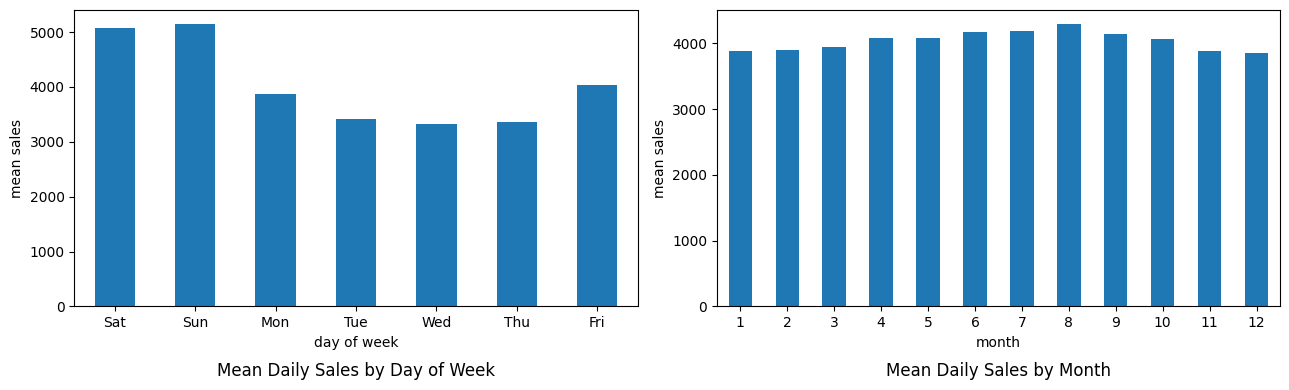

In [ ]:
# basic statistics, missing values, outliers, and patterns, on the raw daily sales
missing = df_calendar['sales'].isna()
print(f"days with no sales data: {missing.sum()} "
      f"({df_calendar.loc[missing, 'date'].min()} to {df_calendar.loc[missing, 'date'].max()}, after the sales file ends)")
print('days with an event (NaN in the event columns just means no event):',
      df_calendar[['event_type_1', 'event_type_2']].notna().sum().to_dict())

raw = df_calendar[~missing]
period = np.where(raw['date'] <= TRAIN_END, 'train', 'test')
stats = raw.groupby(period)['sales'].agg(['count', 'min', 'max', 'mean', 'std']).loc[['train', 'test']]
stats.loc['all'] = raw['sales'].agg(['count', 'min', 'max', 'mean', 'std'])
stats['count'] = stats['count'].astype(int)
print()
print(stats.round(1))

print('\nlowest-sales days:')
print(raw.nsmallest(6, 'sales')[['date', 'weekday', 'event_name_1', 'sales']].to_string(index=False))

# weekly and yearly patterns
days_order = ['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
raw.groupby('weekday')['sales'].mean().reindex(days_order).rename(lambda d: d[:3]).plot.bar(ax=ax1, rot=0)
raw.groupby('month')['sales'].mean().plot.bar(ax=ax2, rot=0)
ax1.set(xlabel='day of week', ylabel='mean sales')
ax2.set(xlabel='month', ylabel='mean sales')
bottom_title(ax1, 'Mean Daily Sales by Day of Week')
bottom_title(ax2, 'Mean Daily Sales by Month')
plt.tight_layout()
plt.show()

In [ ]:
df_master = df_calendar.copy()  # create master dataframe to lookup trues later in test

# deal with missing values: calendar df is larger than sales
df_master = df_master.dropna(subset='sales')

# fill in outliers with interpolated values. The threshold uses training days only
train_days = df_master['date'] <= TRAIN_END
m = df_master.loc[train_days, 'sales'].mean()
std = df_master.loc[train_days, 'sales'].std()
lb = m - 3 * std
outliers = df_master['sales'] < lb
print(f'outlier days filled: {int(outliers.sum())}')
print(df_master.loc[outliers, ['date', 'weekday', 'sales']].to_string(index=False))
df_master['sales'] = df_master['sales'].mask(outliers).interpolate(method='linear')

# create working df for lstm
# drop less useful columns
df = df_master.drop(columns=['snap_TX', 'snap_WI', 'weekday', 'wm_yr_wk', 'date', 'event_name_1', 'event_name_2', 'd', 'year'])

# convert wday and month to sin and cos
days = 7
months = 12

df['wday_sin'] = np.sin(2 * np.pi * df['wday'] / days)
df['wday_cos'] = np.cos(2 * np.pi * df['wday'] / days)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / months)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / months)
df = df.drop(columns=['wday', 'month'])

# one-hot encode
df = pd.get_dummies(df, columns=['event_type_1', 'event_type_2'])

# lastly bump sales to col 0 for convenience
df = df[['sales'] + [col for col in df.columns if col != 'sales']]

print(f"master: {df_master.shape}, working: {df.shape}")

df.columns.tolist()

outlier days filled: 5
      date   weekday  sales
2011-12-25    Sunday    0.0
2012-12-25   Tuesday    0.0
2013-12-25 Wednesday    0.0
2014-12-25  Thursday    0.0
2015-12-25    Friday    0.0
master: (1941, 15), working: (1941, 12)


['sales',
 'snap_CA',
 'wday_sin',
 'wday_cos',
 'month_sin',
 'month_cos',
 'event_type_1_Cultural',
 'event_type_1_National',
 'event_type_1_Religious',
 'event_type_1_Sporting',
 'event_type_2_Cultural',
 'event_type_2_Religious']

In [ ]:
# date lookup for the date-based split and the forecast tests
dates = df_master['date'].tolist()                              # dates[i] is the date of row i in df
row_of = {d: i for i, d in enumerate(dates)}                    # '2015-04-30' -> its row number in df
actual_sales = df_calendar.loc[df.index, 'sales'].to_numpy()    # real sales (before outlier filling), for scoring
n_train = row_of[TRAIN_END] + 1
print(f'train: {dates[0]} to {TRAIN_END} ({n_train} days, {n_train / len(dates):.1%}), '
      f'test: {dates[n_train]} to {dates[-1]} ({len(dates) - n_train} days)')

train: 2011-01-29 to 2015-04-30 (1553 days, 80.0%), test: 2015-05-01 to 2016-05-22 (388 days)


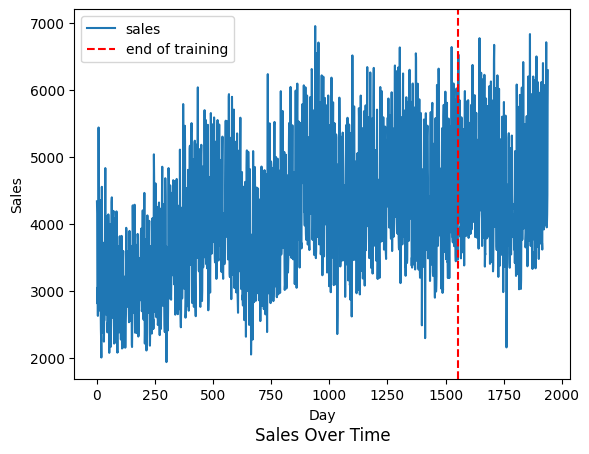

In [ ]:
# quick plot to visualize data
df['sales'].plot()
plt.axvline(row_of[TRAIN_END], color='red', linestyle='--', label='end of training')
plt.legend()
plt.xlabel('Day')
plt.ylabel('Sales')
plt.title('Sales Over Time', y=-0.15, verticalalignment='top')
plt.show()

## 2. Construct LSTM network training pipeline

In [ ]:
@dataclass
class TrainingParameters:
    features: list[str]                  # input columns
    scaler: MinMaxScaler = field(default_factory=MinMaxScaler)
    hidden_size: int = 32                # units per LSTM layer
    lstm_layers: int = 1
    dropout: float = 0.0                 # between LSTM layers, so only used when lstm_layers > 1
    debug: bool = False
    train_end: str = TRAIN_END           # last training day
    sequence_length: int = 90
    prediction_length: int = 28          # aka horizon
    batch_size: int = 32
    learning_rate: float = 1e-3
    epochs: int = 50
    optimizer: type = torch.optim.Adam
    loss_function: type = nn.L1Loss      # mean absolute error
    seed: int | None = None              # optional: none = no seed

    def __post_init__(self):
        self.features = ['sales'] + [c for c in self.features if c != 'sales']

        # build the model from the settings above, so the sizes always match
        if self.seed is not None: torch.manual_seed(self.seed)
        self.model = nn.Sequential(
            nn.LSTM(len(self.features), self.hidden_size, self.lstm_layers, batch_first=True,
                    dropout=self.dropout if self.lstm_layers > 1 else 0.0),
            LSTMOutput(),
            nn.Linear(self.hidden_size, self.prediction_length),
        )

class LSTMOutput(nn.Module):
    def forward(self, lstm_output):
        out, _ = lstm_output          # drop (h, c)
        return out[:, -1, :]          # (batch, hidden_size)


def _train_test_split(p: TrainingParameters, df):
    '''split the data into training and test windows, normalize, and convert to tensors. return the data loader'''
    df = df[p.features].copy()
    split = row_of[p.train_end] + 1                              # first test day: 2015-05-01

    # normalize with training-day statistics only
    scaler = p.scaler.fit(df[['sales']].iloc[:split])
    df['sales'] = scaler.transform(df[['sales']])

    # convert to tensors
    data = torch.tensor(df.to_numpy(dtype='float32'))
    sales = data[:, 0]

    X_train, y_train, X_test, y_test = [], [], [], []
    for start in range(len(data) - p.sequence_length - p.prediction_length + 1):
        first_out = start + p.sequence_length
        end_out = first_out + p.prediction_length
        x = data[start:first_out]                # (sequence_length, features)
        y = sales[first_out:end_out]             # (pred_length,)
        if end_out <= split:                     # all "out" days are training days
            X_train.append(x)
            y_train.append(y)
        elif first_out >= split:                 # all "out" days are test days
            X_test.append(x)
            y_test.append(y)

    X_train, y_train = torch.stack(X_train), torch.stack(y_train)
    X_test, y_test = torch.stack(X_test), torch.stack(y_test)

    train_batches = DataLoader(TensorDataset(X_train, y_train), batch_size=p.batch_size, shuffle=True)

    return (train_batches, X_test, y_test)


def train_test(p: TrainingParameters, train_batches, X_test, y_test):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    p.model.to(device)
    optimizer = p.optimizer(p.model.parameters(), lr=p.learning_rate)
    loss_function = p.loss_function()
    train_losses = []
    test_losses = []
    real_maes = []

    for e in range(p.epochs):
        p.model.train()
        epoch_losses = []

        for inputs, outputs in train_batches:
            inputs, outputs = inputs.to(device), outputs.to(device)
            optimizer.zero_grad()
            preds = p.model(inputs)
            loss = loss_function(preds, outputs)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        crnt_train_loss = sum(epoch_losses) / len(epoch_losses)
        train_losses.append(crnt_train_loss)

        p.model.eval()
        with torch.no_grad():
            test_preds = p.model(X_test.to(device))
            test_loss = loss_function(test_preds, y_test.to(device)).item()
            real_mae = mae(unscale(p, test_preds), unscale(p, y_test))   # real sales, units/day
        test_losses.append(test_loss)
        real_maes.append(real_mae)

        if (e + 1) % max(1, p.epochs // 10) == 0:
            print(f"epoch {e + 1} of {p.epochs} -- train: {crnt_train_loss:.4f},  test: {test_loss:.4f},  real MAE (sales): {real_mae:.1f}")

    return train_losses, test_losses, real_maes


LOSS_NAMES = {'L1Loss': 'MAE', 'MSELoss': 'MSE'}

def settings(p):
    """the settings that change between experiments, for the loss-plot card and the results table"""
    return {'input days': p.sequence_length, 'input columns': len(p.features), 'hidden size': p.hidden_size,
            'LSTM layers': p.lstm_layers, 'dropout': p.dropout, 'batch size': p.batch_size,
            'learning rate': p.learning_rate, 'epochs': p.epochs, 'optimizer': p.optimizer.__name__,
            'loss': LOSS_NAMES.get(p.loss_function.__name__, p.loss_function.__name__)}


def plot_losses(p, train_losses, test_losses, real_maes):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(train_losses, label='train loss')
    ax.plot(test_losses, label='test loss')
    ax.set(xlabel='epoch', ylabel='loss (scaled sales)')

    # real MAE in real sales is in the hundreds, so it gets its own axis on the right
    ax2 = ax.twinx()
    ax2.plot(real_maes, color='tab:green', linestyle='--', label='real MAE')
    ax2.set_ylabel('real MAE (units/day)')
    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [line.get_label() for line in lines])
    bottom_title(ax, 'Loss and real MAE Over Epochs')

    # parameter card to the right of the plot, past the MAE axis
    card = '\n'.join(f'{name:<15}{value}' for name, value in settings(p).items())
    ax.text(1.16, 1.0, card, transform=ax.transAxes, va='top', ha='left', family='monospace', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.7', facecolor='whitesmoke', edgecolor='lightgray'))
    plt.show()


def unscale(p, t):
    """scaled sales tensor -> real sales, as a numpy array of the same shape"""
    return p.scaler.inverse_transform(t.cpu().numpy().reshape(-1, 1)).reshape(t.shape)


mae_loss = nn.L1Loss()
def mae(pred, actual):
    return mae_loss(torch.as_tensor(pred, dtype=torch.float32), torch.as_tensor(actual, dtype=torch.float32)).item()

### Experiments
Each configuration trains on the full training period (2011-01-29 to 2015-04-30) and is scored on the test period (2015-05-01 to 2016-05-22). The 90-day configuration with the lowest real MAE is used for both tests.

In [ ]:
print(f"Reminder: all possible input features are...\n{df.columns.tolist()[1:]}")

Reminder: all possible input features are...
['snap_CA', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos', 'event_type_1_Cultural', 'event_type_1_National', 'event_type_1_Religious', 'event_type_1_Sporting', 'event_type_2_Cultural', 'event_type_2_Religious']


epoch 5 of 50 -- train: 0.0113,  test: 0.0119,  real MAE (sales): 424.2
epoch 10 of 50 -- train: 0.0084,  test: 0.0090,  real MAE (sales): 367.4
epoch 15 of 50 -- train: 0.0073,  test: 0.0081,  real MAE (sales): 342.9
epoch 20 of 50 -- train: 0.0065,  test: 0.0071,  real MAE (sales): 313.7
epoch 25 of 50 -- train: 0.0062,  test: 0.0073,  real MAE (sales): 320.3
epoch 30 of 50 -- train: 0.0060,  test: 0.0069,  real MAE (sales): 308.2
epoch 35 of 50 -- train: 0.0059,  test: 0.0068,  real MAE (sales): 306.2
epoch 40 of 50 -- train: 0.0058,  test: 0.0068,  real MAE (sales): 307.1
epoch 45 of 50 -- train: 0.0057,  test: 0.0066,  real MAE (sales): 303.1
epoch 50 of 50 -- train: 0.0057,  test: 0.0068,  real MAE (sales): 308.9


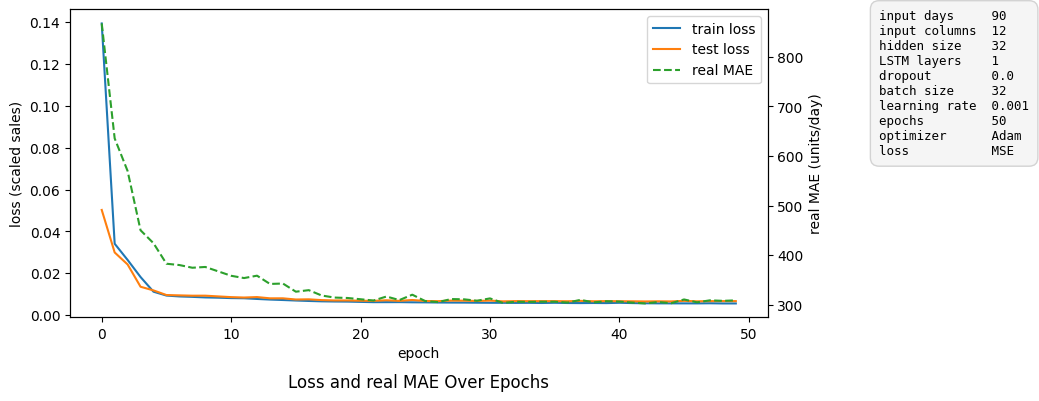

epoch 5 of 50 -- train: 0.0743,  test: 0.0764,  real MAE (sales): 382.4
epoch 10 of 50 -- train: 0.0649,  test: 0.0686,  real MAE (sales): 343.5
epoch 15 of 50 -- train: 0.0586,  test: 0.0634,  real MAE (sales): 317.6
epoch 20 of 50 -- train: 0.0567,  test: 0.0609,  real MAE (sales): 304.8
epoch 25 of 50 -- train: 0.0551,  test: 0.0614,  real MAE (sales): 307.2
epoch 30 of 50 -- train: 0.0543,  test: 0.0607,  real MAE (sales): 303.9
epoch 35 of 50 -- train: 0.0544,  test: 0.0614,  real MAE (sales): 307.6
epoch 40 of 50 -- train: 0.0527,  test: 0.0583,  real MAE (sales): 291.8
epoch 45 of 50 -- train: 0.0520,  test: 0.0613,  real MAE (sales): 307.1
epoch 50 of 50 -- train: 0.0510,  test: 0.0580,  real MAE (sales): 290.5


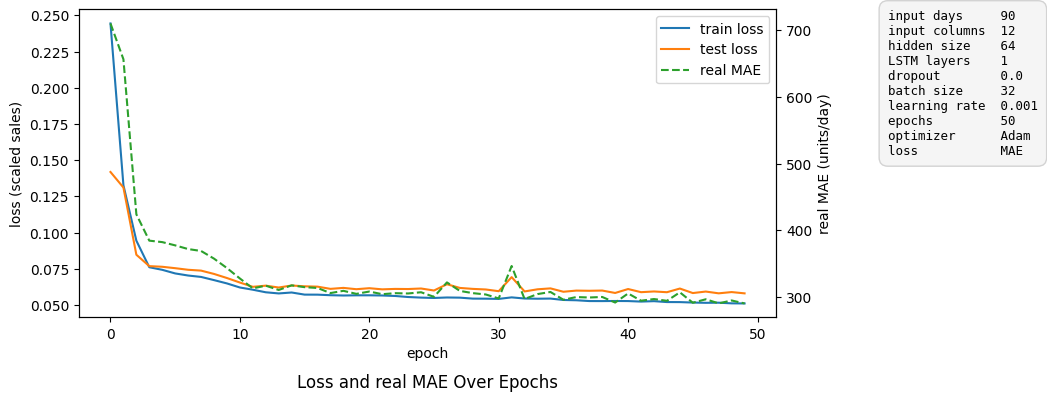

epoch 10 of 100 -- train: 0.0699,  test: 0.0735,  real MAE (sales): 367.9
epoch 20 of 100 -- train: 0.0583,  test: 0.0615,  real MAE (sales): 307.7
epoch 30 of 100 -- train: 0.0553,  test: 0.0598,  real MAE (sales): 299.2
epoch 40 of 100 -- train: 0.0531,  test: 0.0598,  real MAE (sales): 299.2
epoch 50 of 100 -- train: 0.0504,  test: 0.0566,  real MAE (sales): 283.6
epoch 60 of 100 -- train: 0.0489,  test: 0.0565,  real MAE (sales): 282.9
epoch 70 of 100 -- train: 0.0469,  test: 0.0554,  real MAE (sales): 277.3
epoch 80 of 100 -- train: 0.0453,  test: 0.0550,  real MAE (sales): 275.3
epoch 90 of 100 -- train: 0.0442,  test: 0.0577,  real MAE (sales): 288.7
epoch 100 of 100 -- train: 0.0434,  test: 0.0564,  real MAE (sales): 282.2


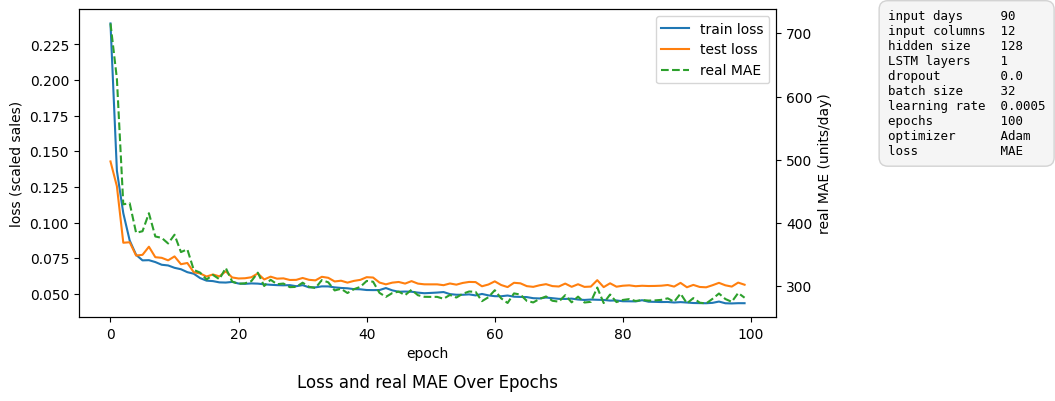

epoch 10 of 100 -- train: 0.0596,  test: 0.0733,  real MAE (sales): 366.8
epoch 20 of 100 -- train: 0.0530,  test: 0.0605,  real MAE (sales): 303.0
epoch 30 of 100 -- train: 0.0504,  test: 0.0590,  real MAE (sales): 295.5
epoch 40 of 100 -- train: 0.0469,  test: 0.0582,  real MAE (sales): 291.4
epoch 50 of 100 -- train: 0.0450,  test: 0.0578,  real MAE (sales): 289.4
epoch 60 of 100 -- train: 0.0428,  test: 0.0571,  real MAE (sales): 285.8
epoch 70 of 100 -- train: 0.0415,  test: 0.0574,  real MAE (sales): 287.3
epoch 80 of 100 -- train: 0.0404,  test: 0.0559,  real MAE (sales): 280.1
epoch 90 of 100 -- train: 0.0394,  test: 0.0578,  real MAE (sales): 289.5
epoch 100 of 100 -- train: 0.0381,  test: 0.0575,  real MAE (sales): 287.7


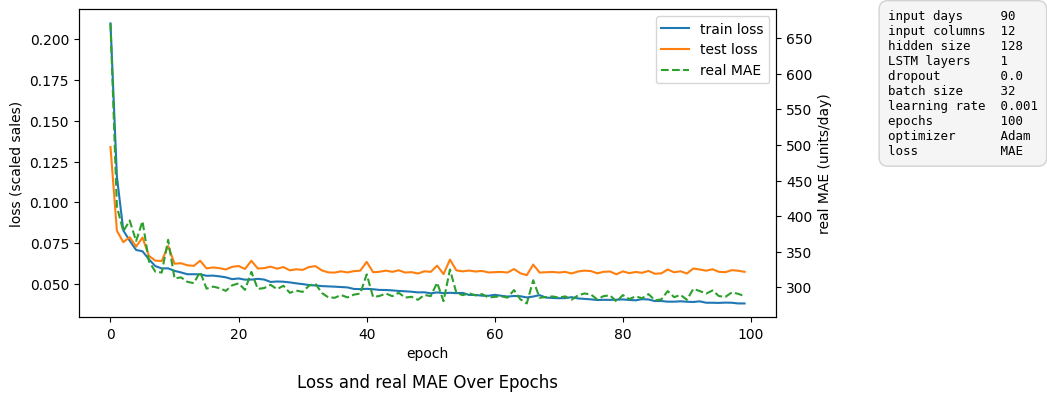

epoch 10 of 100 -- train: 0.0082,  test: 0.0102,  real MAE (sales): 394.2
epoch 20 of 100 -- train: 0.0059,  test: 0.0073,  real MAE (sales): 322.6
epoch 30 of 100 -- train: 0.0055,  test: 0.0065,  real MAE (sales): 298.6
epoch 40 of 100 -- train: 0.0051,  test: 0.0063,  real MAE (sales): 300.2
epoch 50 of 100 -- train: 0.0048,  test: 0.0071,  real MAE (sales): 328.8
epoch 60 of 100 -- train: 0.0045,  test: 0.0058,  real MAE (sales): 288.4
epoch 70 of 100 -- train: 0.0043,  test: 0.0059,  real MAE (sales): 288.7
epoch 80 of 100 -- train: 0.0041,  test: 0.0057,  real MAE (sales): 283.2
epoch 90 of 100 -- train: 0.0039,  test: 0.0054,  real MAE (sales): 278.2
epoch 100 of 100 -- train: 0.0036,  test: 0.0054,  real MAE (sales): 277.1


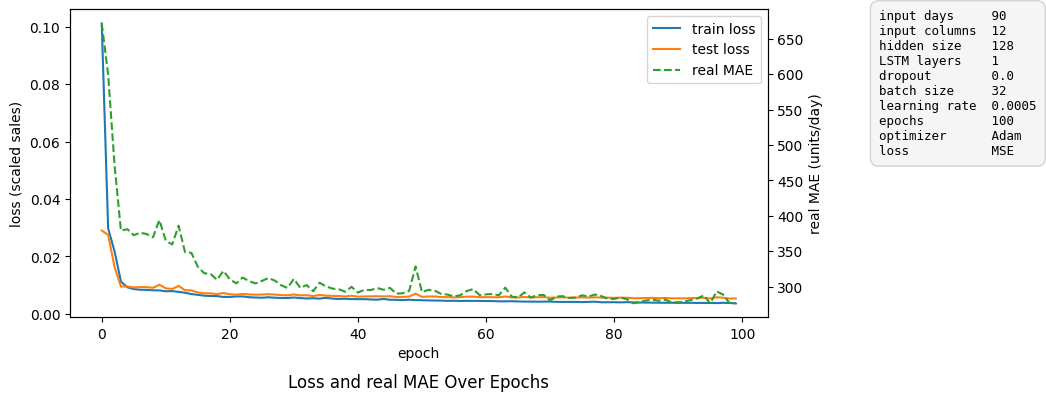

epoch 10 of 100 -- train: 0.0065,  test: 0.0070,  real MAE (sales): 313.5
epoch 20 of 100 -- train: 0.0055,  test: 0.0062,  real MAE (sales): 297.1
epoch 30 of 100 -- train: 0.0049,  test: 0.0058,  real MAE (sales): 288.1
epoch 40 of 100 -- train: 0.0045,  test: 0.0059,  real MAE (sales): 295.9
epoch 50 of 100 -- train: 0.0041,  test: 0.0057,  real MAE (sales): 285.1
epoch 60 of 100 -- train: 0.0038,  test: 0.0056,  real MAE (sales): 287.9
epoch 70 of 100 -- train: 0.0034,  test: 0.0057,  real MAE (sales): 291.4
epoch 80 of 100 -- train: 0.0032,  test: 0.0054,  real MAE (sales): 284.4
epoch 90 of 100 -- train: 0.0030,  test: 0.0052,  real MAE (sales): 278.0
epoch 100 of 100 -- train: 0.0028,  test: 0.0051,  real MAE (sales): 275.4


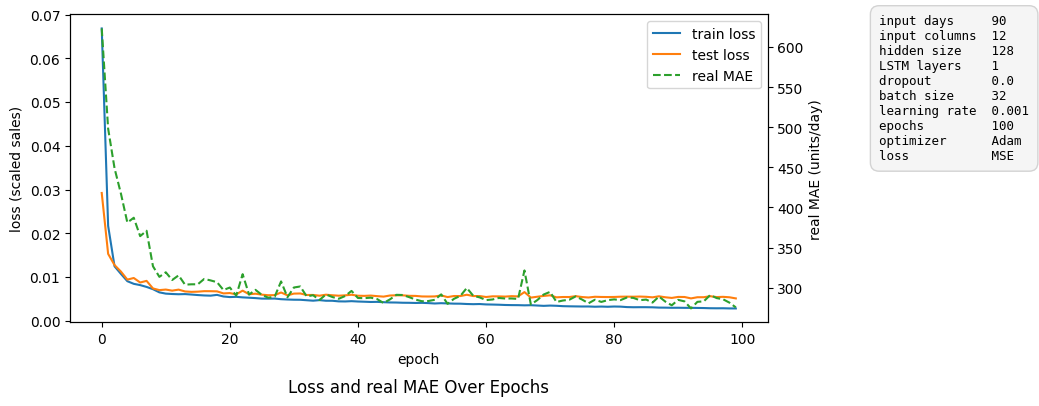

,input days,input columns,hidden size,LSTM layers,dropout,batch size,learning rate,epochs,optimizer,loss,real MAE
0,90,12,32,1,0.0,32,0.0010,50,Adam,MSE,308.9
1,90,12,64,1,0.0,32,0.0010,50,Adam,MAE,290.5
2,90,12,128,1,0.0,32,0.0005,100,Adam,MAE,282.2
3,90,12,128,1,0.0,32,0.0010,100,Adam,MAE,287.7
4,90,12,128,1,0.0,32,0.0005,100,Adam,MSE,277.1
5,90,12,128,1,0.0,32,0.0010,100,Adam,MSE,275.4


In [ ]:
# experiments: each config trains on 2011-01-29 to 2015-04-30 and is scored on the test period
ALL = list(df.columns)
p_list = [
    TrainingParameters(features=ALL, loss_function=nn.MSELoss),     # the assignment's starting configuration
    TrainingParameters(features=ALL, hidden_size=64), # MAE loss instead of MSE + more hidden units
    #TrainingParameters(features=ALL, hidden_size=128, epochs=100, learning_rate=5e-4),
    #TrainingParameters(features=ALL, hidden_size=128, lstm_layers=2, dropout=0.2, epochs=100),
    #TrainingParameters(features=ALL, hidden_size=64, sequence_length=56, epochs=100),
    #TrainingParameters(features=ALL, hidden_size=64, sequence_length=364, epochs=100),
    #TrainingParameters(features=ALL, hidden_size=64, loss_function=nn.HuberLoss, epochs=100),
    #TrainingParameters(features=ALL, hidden_size=64, epochs=100),                          # epochs only
    #TrainingParameters(features=ALL, hidden_size=64, learning_rate=5e-4, epochs=100),      # + lower LR
    TrainingParameters(features=ALL, hidden_size=128, learning_rate=5e-4, epochs=100),
    TrainingParameters(features=ALL, hidden_size=128, epochs=100),
    TrainingParameters(features=ALL, hidden_size=128, learning_rate=5e-4, epochs=100, loss_function=nn.MSELoss),
    TrainingParameters(features=ALL, hidden_size=128, epochs=100, loss_function=nn.MSELoss),
]

results = []
for p in p_list:
    train_batches, X_test, y_test = _train_test_split(p, df)
    train_losses, test_losses, real_maes = train_test(p, train_batches, X_test, y_test)
    plot_losses(p, train_losses, test_losses, real_maes)
    results.append({**settings(p), 'real MAE': real_maes[-1]})     # real sales, comparable across losses

experiments = pd.DataFrame(results)
experiments.round({'real MAE': 1})

## 3. Testing: Predict Sales for 28 Days

In [ ]:
# grab best model from testing: the 90-day config with the lowest real MAE (the tests require a 90-day input)
candidates = experiments[experiments['input days'] == 90]
best = p_list[candidates['real MAE'].idxmin()]
print('model used for all tests:', settings(best))


@torch.no_grad()
def forecast(p, today):
    """Assume `today` is today. Give the model the 90 days ending on today (including today),
    predict the next 28 days, and return (predicted, actual, baselines) in real sales."""
    assert p.prediction_length <= 28, 'same day last month would need days after today'
    scaled = df[p.features].copy()
    scaled['sales'] = p.scaler.transform(df[['sales']])               # same scaling as training
    data = torch.tensor(scaled.to_numpy(dtype='float32'))

    t = row_of[today]
    x = data[t - p.sequence_length + 1 : t + 1]                       # previous 90 days, including today
    p.model.eval()
    device = next(p.model.parameters()).device
    pred = p.model(x.unsqueeze(0).to(device)).cpu().numpy()
    pred = p.scaler.inverse_transform(pred.reshape(-1, 1)).ravel()

    future = slice(t + 1, t + 1 + p.prediction_length)                # the 28 days after today
    actual = actual_sales[future]
    baselines = {
        'same day last month': actual_sales[t + 1 - 28 : t + 1 - 28 + p.prediction_length],     # 4 weeks earlier
        'same day last year': actual_sales[t + 1 - 364 : t + 1 - 364 + p.prediction_length],    # 52 weeks earlier
    }
    return pred, actual, baselines


def plot_forecast(ax, title, pred, actual, baselines):
    days = np.arange(1, len(actual) + 1)
    ax.plot(days, actual, 'o-', color='black', markersize=3, label='actual')
    ax.plot(days, pred, 's--', markersize=3, label='LSTM')
    for (name, values), style in zip(baselines.items(), [':', '-.']):
        ax.plot(days, values, style, linewidth=1.2, label=name)
    ax.set(xlabel='days ahead', ylabel='sales')
    ax.legend(loc='lower left', framealpha=0.4)
    bottom_title(ax, title)

model used for all tests: {'input days': 90, 'input columns': 12, 'hidden size': 128, 'LSTM layers': 1, 'dropout': 0.0, 'batch size': 32, 'learning rate': 0.001, 'epochs': 100, 'optimizer': 'Adam', 'loss': 'MSE'}


### Test 1: Beginning of Test Period

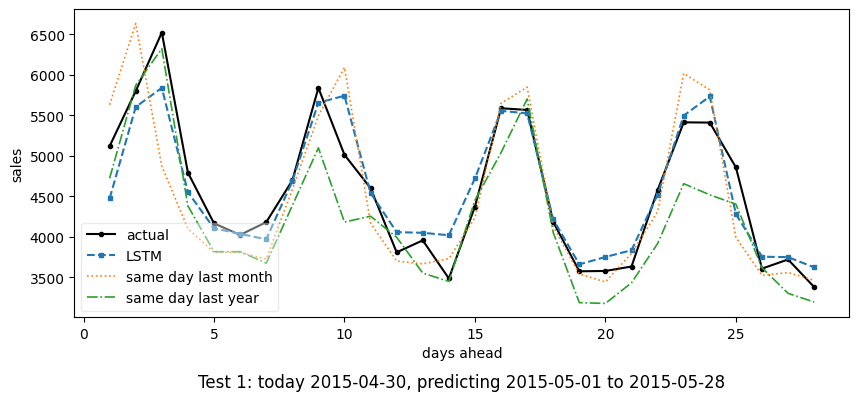

MAE -- LSTM: 224.2   same day last month: 380.9   same day last year: 366.2


In [ ]:
# Test 1: today is the last day of the training period
today = '2015-04-30'
pred, actual, baselines = forecast(best, today)
t = row_of[today]

fig, ax = plt.subplots(figsize=(10, 4))
plot_forecast(ax, f'Test 1: today {today}, predicting {dates[t + 1]} to {dates[t + best.prediction_length]}',
              pred, actual, baselines)
plt.show()
print(f'MAE -- LSTM: {mae(pred, actual):.1f}   '
      + '   '.join(f'{name}: {mae(values, actual):.1f}' for name, values in baselines.items()))

### Test 2: Forecasts from Within the Test Period

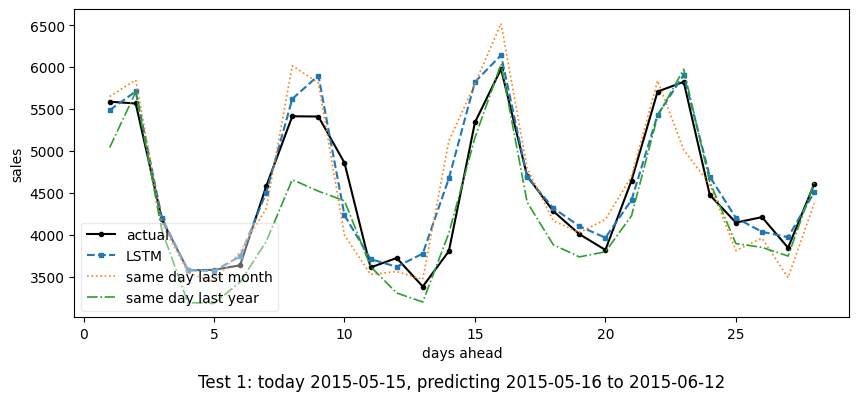

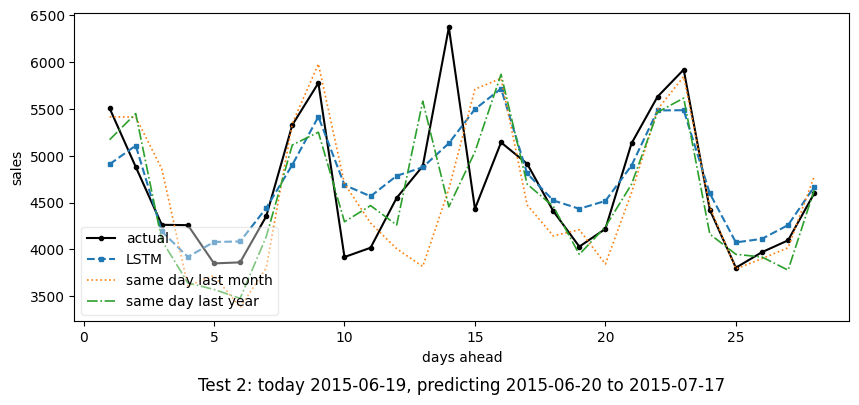

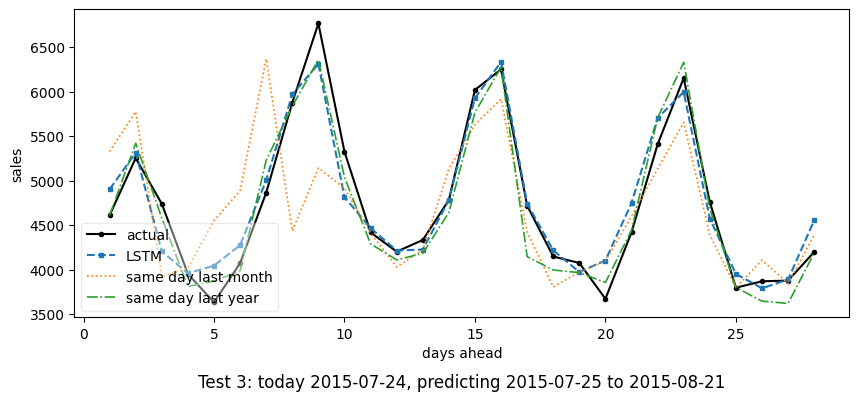

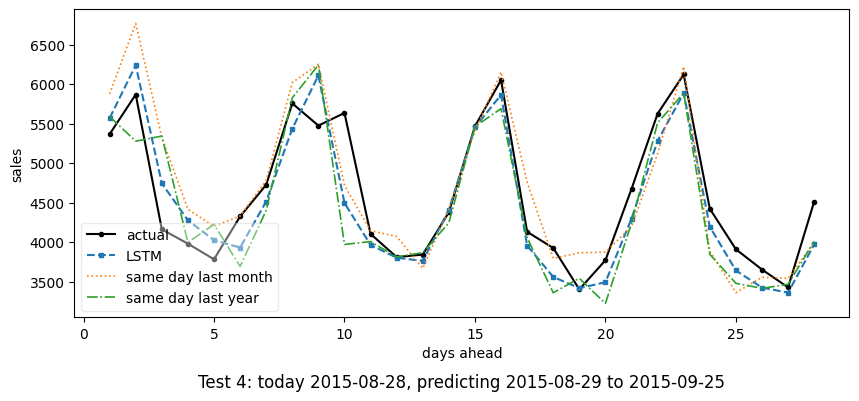

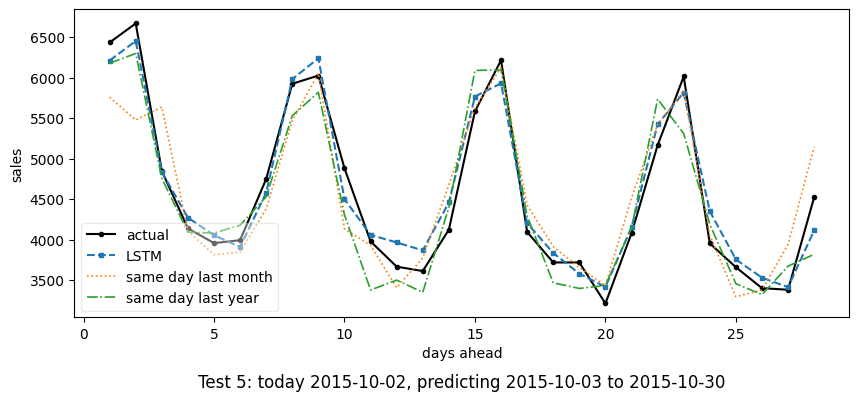

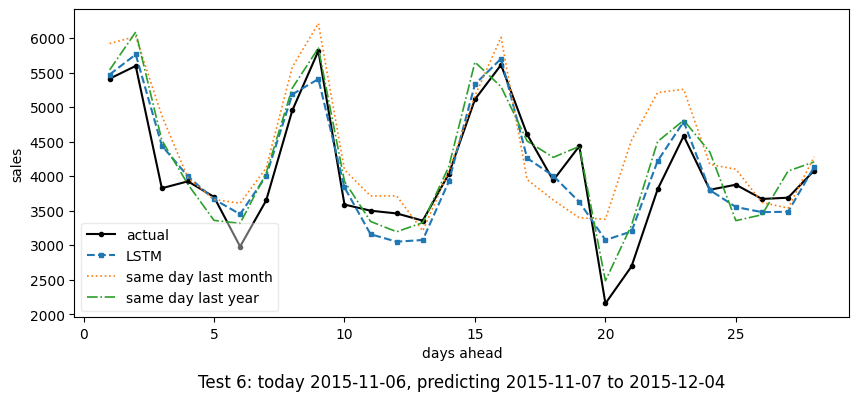

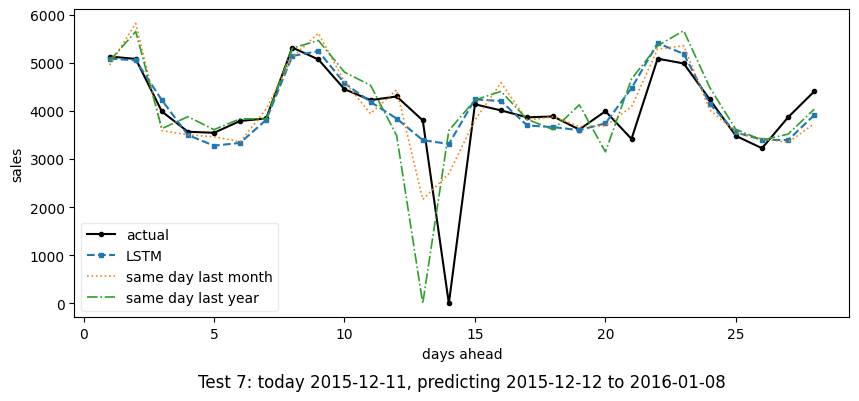

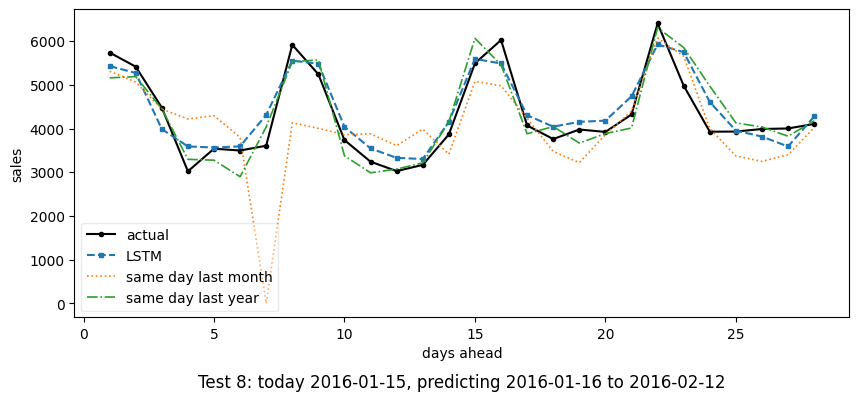

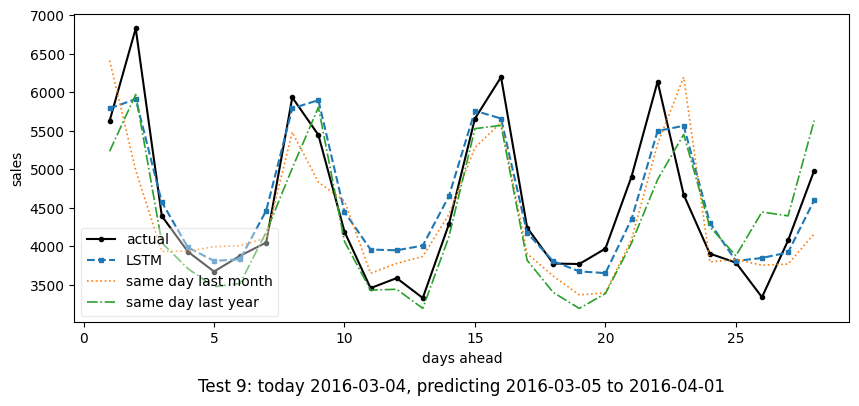

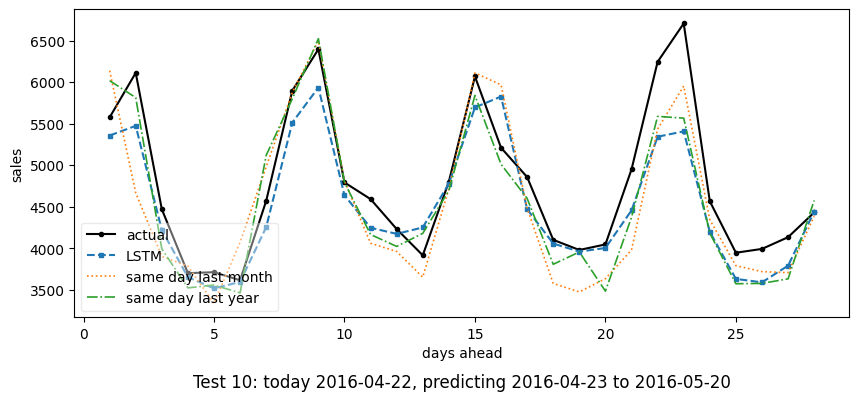

,test,today,predict sales for,LSTM MAE,same day last month MAE,same day last year MAE
0,1,2015-05-15,2015-05-16 to 2015-06-12,194.8,299.9,299.8
1,2,2015-06-19,2015-06-20 to 2015-07-17,341.2,427.2,373.2
2,3,2015-07-24,2015-07-25 to 2015-08-21,187.4,470.1,170.2
3,4,2015-08-28,2015-08-29 to 2015-09-25,284.7,368.9,372.3
4,5,2015-10-02,2015-10-03 to 2015-10-30,185.2,324.5,294.5
5,6,2015-11-06,2015-11-07 to 2015-12-04,290.8,496.1,307.9
6,7,2015-12-11,2015-12-12 to 2016-01-08,344.9,428.0,584.1
7,8,2016-01-15,2016-01-16 to 2016-02-12,321.4,649.7,317.7
8,9,2016-03-04,2016-03-05 to 2016-04-01,335.1,478.8,447.8
9,10,2016-04-22,2016-04-23 to 2016-05-20,323.5,409.3,329.7


In [ ]:
# Test 2: forecasts from within the test period
test_dates = ['2015-05-15', '2015-06-19', '2015-07-24', '2015-08-28', '2015-10-02',
              '2015-11-06', '2015-12-11', '2016-01-15', '2016-03-04', '2016-04-22']

rows = []
for i, today in enumerate(test_dates, start=1):
    pred, actual, baselines = forecast(best, today)
    t = row_of[today]
    predict_range = f'{dates[t + 1]} to {dates[t + best.prediction_length]}'

    fig, ax = plt.subplots(figsize=(10, 4))
    plot_forecast(ax, f'Test {i}: today {today}, predicting {predict_range}', pred, actual, baselines)
    plt.show()

    row = {'test': i, 'today': today, 'predict sales for': predict_range, 'LSTM MAE': mae(pred, actual)}
    row.update({f'{name} MAE': mae(values, actual) for name, values in baselines.items()})
    rows.append(row)

table = pd.DataFrame(rows)
average = {'test': 'average', 'today': '', 'predict sales for': ''}
average.update({col: table[col].mean() for col in table.columns if col.endswith('MAE')})
table = pd.concat([table, pd.DataFrame([average])], ignore_index=True)
table.round(1)